# Modelo No Supervisado K-Means

**Materia:** Aprendizaje Automático 2026 2C

**Alumna:** SANDRA VARGAS

**Dataset:** dataset_segmentacion_clientes.csv (provisto en el campus de la materia)

**Objetivo:** identificar cuántos segmentos latentes de clientes existen a partir de sus comportamientos de compra y uso del sitio, sin etiquetas previas.

**Qué patrones buscar:**

    o Grupos con frecuencia alta pero ticket bajo y alta sensibilidad a descuentos.

    o Grupos con frecuencia baja pero ticket alto y baja sensibilidad (compras esporádicas pero grandes).

    o Grupos con tiempo en sitio y tasa de devoluciones diferenciados (p. ej., exploran mucho y devuelven más vs. exploran poco y devuelven menos).

**Cómo validarlo:**

    o Comparar k=2..6 usando método del codo para justificar qué valor de k es razonable.

    o Analizar los centroides por cluster para describir perfiles (p. ej., “Cluster 1: alta frecuencia + ticket medio + sensibilidad media, foco para promociones; Cluster 2: ticket alto + baja sensibilidad, foco en upselling premium”, etc.).

En esta instancia deberás compartir tu jupyter notebook en tu repositorio GIT.

# Carga de las Librerías

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
from scipy.spatial.distance import cdist

import os
os.environ["OMP_NUM_THREADS"] = "3"

import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=UserWarning)

# Carga del dataset

In [7]:
# Carga del dataset desde un archivo tipo CSV
df = pd.read_csv("dataset_segmentacion_clientes.csv", encoding="utf-8")

df.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522


In [8]:
# Eliminar las columnas de ruido gaussiano y uniforme del dataset
df = df.drop(columns=["noise_gauss", "noise_uniform"])

# Verificar las columnas restantes
df.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
0,11.152508,181.300834,33.564036,1.000000,0.800000
1,12.053451,178.637272,35.432081,0.784974,0.000000
2,2.203006,450.185298,7.030757,0.898297,0.000000
3,4.233314,89.006342,10.834453,0.000000,0.800000
4,1.716799,449.773982,7.254548,0.000000,0.003279


# Análisis Exploratorio de Datos (EDA)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   purchase_freq_month   700 non-null    float64
 1   avg_basket_usd        700 non-null    float64
 2   time_on_site_min      700 non-null    float64
 3   discount_sensitivity  700 non-null    float64
 4   returns_rate          700 non-null    float64
dtypes: float64(5)
memory usage: 27.5 KB


In [10]:
df.describe()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
count,700.000000,700.000000,700.000000,700.000000,700.000000
mean,5.875724,248.173491,16.784799,0.425083,0.337194
std,4.471079,154.904372,12.914111,0.431467,0.356623
min,0.100000,86.994100,3.163206,0.000000,0.000000
25%,2.278418,90.766945,6.603950,0.000000,0.000000
50%,4.134580,180.223799,9.974407,0.296475,0.165559
75%,11.214919,449.719033,34.341360,1.000000,0.800000
max,14.603388,452.973583,38.348156,1.000000,0.800000


In [12]:
# Diagnóstico de valores faltantes
print("Valores faltantes por columna:")
print(df.isnull().sum())

# Diagnóstico de registros duplicados
print("\nCantidad de registros duplicados:", df.duplicated().sum())
if df.duplicated().sum() > 0:
    display(df[df.duplicated()])
else:
    print("\nNo hay registros duplicados.")

Valores faltantes por columna:
purchase_freq_month     0
avg_basket_usd          0
time_on_site_min        0
discount_sensitivity    0
returns_rate            0
dtype: int64

Cantidad de registros duplicados: 0

No hay registros duplicados.


In [13]:
# verificamos si hay valores outliers mediante regla IQR
# Seleccionar las variables numéricas
numericas = [
    'purchase_freq_month',
    'avg_basket_usd',
    'time_on_site_min',
    'discount_sensitivity',
    'returns_rate'
]

# Calcular los límites y contar los posibles outliers
resultados = []

for columna in numericas:
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[columna] < limite_inferior) |
        (df[columna] > limite_superior)
    ]

    resultados.append({
        'Variable': columna,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Limite inferior': limite_inferior,
        'Limite superior': limite_superior,
        'Cantidad outliers': len(outliers),
        'Porcentaje outliers': len(outliers) / len(df) * 100
    })

tabla_outliers = pd.DataFrame(resultados).round(2)
display(tabla_outliers)


,Variable,Q1,Q3,IQR,Limite inferior,Limite superior,Cantidad outliers,Porcentaje outliers
0,purchase_freq_month,2.28,11.21,8.94,-11.13,24.62,0,0.0
1,avg_basket_usd,90.77,449.72,358.95,-447.66,988.15,0,0.0
2,time_on_site_min,6.60,34.34,27.74,-35.00,75.95,0,0.0
3,discount_sensitivity,0.00,1.00,1.00,-1.50,2.50,0,0.0
4,returns_rate,0.00,0.80,0.80,-1.20,2.00,0,0.0


### Descripción del dataset y las variables

El dataset contiene 700 registros y 5 variables relacionadas con el comportamiento de compra de clientes. 

No presenta valores faltantes, no hay registros duplicados ytampoco tiene valores outliers.

Las variables permiten analizar la frecuencia de compra, el importe de las compras, el tiempo de navegación, la sensibilidad a los descuentos y las devoluciones. Todas las variables serán utilizadase para encontrar patrones mediante el modelo de segmentación K-Means.

| Nombre original | Traducción al español | Descripción |
| :--- | :--- | :--- |
| **purchase_freq_month** | Frecuencia de compra mensual | Cantidad de compras que realiza un cliente por mes. |
| **avg_basket_usd** | Importe promedio de compra (USD) | Valor monetario promedio de la cesta o carrito de compra, expresado en dólares estadounidenses. |
| **time_on_site_min** | Tiempo en el sitio (minutos) | Tiempo que el cliente permanece navegando en el sitio web, medido en minutos. |
| **discount_sensitivity** | Sensibilidad a los descuentos | Grado en que el comportamiento de compra del cliente está asociado a los descuentos. |
| **returns_rate** | Tasa de devoluciones | Proporción o frecuencia relativa de las compras que el cliente devuelve. |

# Análisis de Correlación de las Variables

In [16]:
print("Matriz de correlación")
corr = df[numericas].corr()
df.corr()

Matriz de correlación


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
purchase_freq_month,1.000000,-0.488868,0.967234,0.190964,-0.020488
avg_basket_usd,-0.488868,1.000000,-0.426025,-0.077487,0.086050
time_on_site_min,0.967234,-0.426025,1.000000,0.188449,-0.013936
discount_sensitivity,0.190964,-0.077487,0.188449,1.000000,-0.014467
returns_rate,-0.020488,0.086050,-0.013936,-0.014467,1.000000


In [17]:
# Obtener solo las parejas únicas, sin la diagonal
mascara = np.triu(np.ones(corr.shape, dtype=bool), k=1)
principales = (corr.where(mascara).stack().reset_index())
principales.columns = ['Variable 1', 'Variable 2', 'Correlación']

# Ordenar por intensidad absoluta, de mayor a menor
principales['Intensidad'] = principales['Correlación'].abs()
principales = principales.sort_values('Intensidad', ascending=False)

# Mostrar las 5 correlaciones más fuertes
print("\n**** PRINCIPALES CORRELACIONES ****")
print(principales.head(5)[['Variable 1', 'Variable 2', 'Correlación']
    ].to_string(index=False,formatters={'Correlación': '{:.3f}'.format}))


**** PRINCIPALES CORRELACIONES ****
         Variable 1           Variable 2 Correlación
purchase_freq_month     time_on_site_min       0.967
purchase_freq_month       avg_basket_usd      -0.489
     avg_basket_usd     time_on_site_min      -0.426
purchase_freq_month discount_sensitivity       0.191
   time_on_site_min discount_sensitivity       0.188


# Visualizamos la relación entre los tres pares de variables mas correlacionaddas

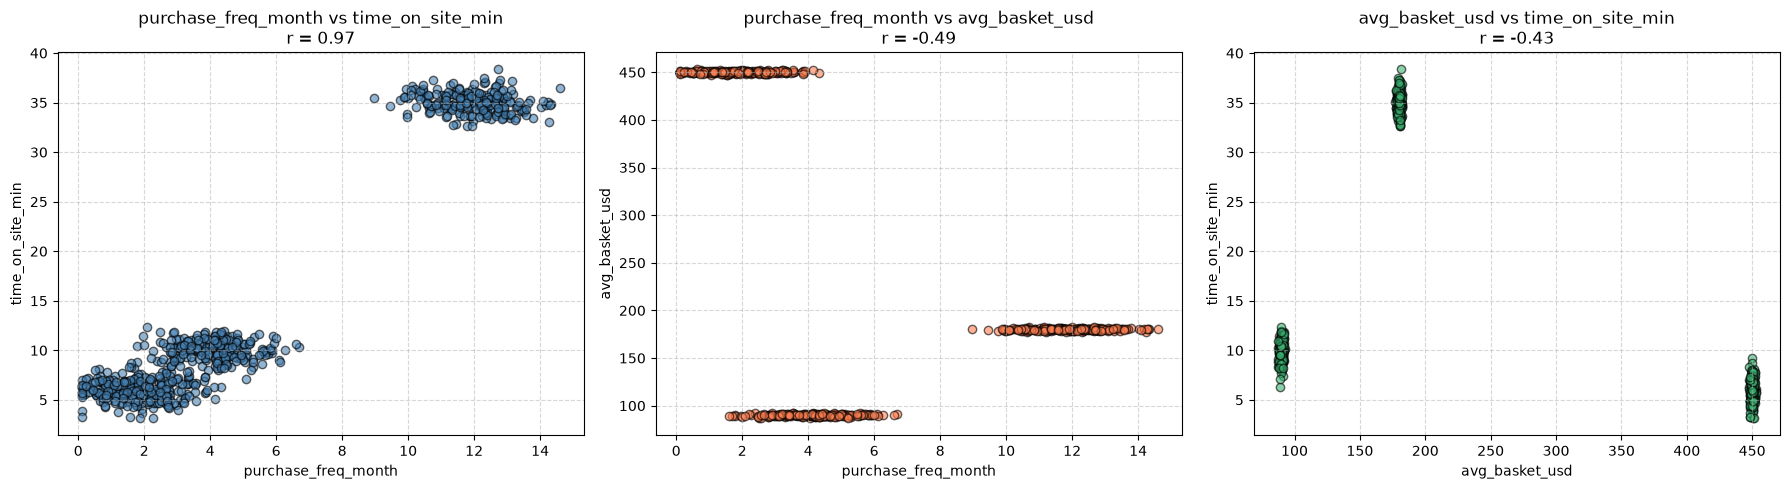

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pares = [
    ('purchase_freq_month', 'time_on_site_min', 'steelblue'),
    ('purchase_freq_month', 'avg_basket_usd', 'coral'),
    ('avg_basket_usd', 'time_on_site_min', 'mediumseagreen')
]

for ax, (x, y, color) in zip(axes, pares):
    ax.scatter(df[x], df[y], alpha=0.6, color=color, edgecolor='k')
    r = corr.loc[x, y]
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f'{x} vs {y}\nr = {r:.2f}')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### Los valores de la matriz de correlación permitió identificar las relaciones entre las variables numéricas y detectó tres pares de asociación: 

### Pares:

     'purchase_freq_month' y  'time_on_site_min'
     'purchase_freq_month' y  'avg_basket_usd'
     'avg_basket_usd', 'time_on_site_min'
     
### Los gráficos nos permiten observar a priori que hay tres grupos de clientes.

# Normalización de los datos
Debemos normalizar ya que Kmeans utiliza distnacia euclidiana.

In [20]:
#Seleccionar la matriz de características numéricas X
X = df[['purchase_freq_month', 'avg_basket_usd', 'time_on_site_min', 'discount_sensitivity', 'returns_rate']]

#Instanciar y aplicar StandardScaler sobre todo el conjunto X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Buscamos el número óptimo de clusters usando Método del Codo y Silhouette Score

#### **Método del codo:** analiza compactación de los cluster y muestra cantidad adecuada de clusters.

#### **Silhouette Score:** evaluamos la distancia entre los cluster. Los valores mas altos, indican cluster mejore definidos.

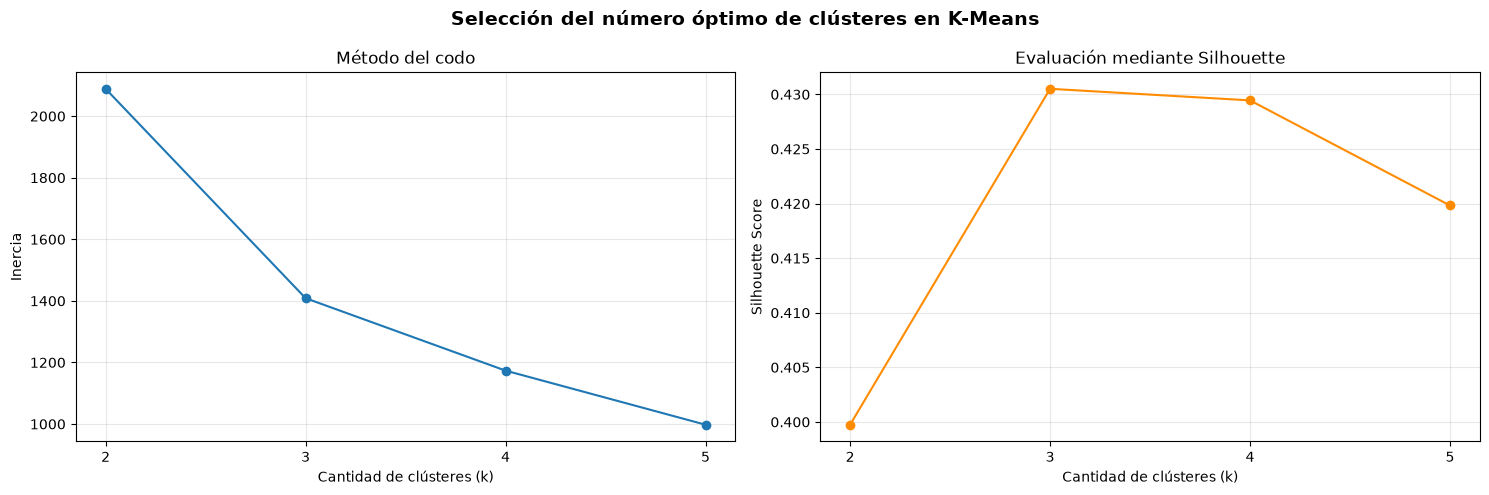

Mejor k según Silhouette: 3
Silhouette Score: 0.4305


In [21]:
# Valores de k a evaluar
valores_k = range(2, 6)

# Listas para guardar los resultados
inercias = []
silhouette_scores = []

# Evaluar cada cantidad de clústeres
for k in valores_k:
    modelo = KMeans(
        init='k-means++',
        n_clusters=k,
        random_state=42,
        n_init=10,
        max_iter=500
    )

    labels = modelo.fit_predict(X_scaled)

    # Método del codo
    inercias.append(modelo.inertia_)

    # Silhouette Score
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)


# Crear una figura con dos gráficos
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Método del codo
axes[0].plot(
    list(valores_k),
    inercias,
    marker='o',
    linestyle='-'
)

axes[0].set_xlabel('Cantidad de clústeres (k)')
axes[0].set_ylabel('Inercia')
axes[0].set_title('Método del codo')
axes[0].set_xticks(list(valores_k))
axes[0].grid(alpha=0.3)

# Gráfico 2: Silhouette Score
axes[1].plot(
    list(valores_k),
    silhouette_scores,
    marker='o',
    linestyle='-',
    color='darkorange'
)

axes[1].set_xlabel('Cantidad de clústeres (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Evaluación mediante Silhouette')
axes[1].set_xticks(list(valores_k))
axes[1].grid(alpha=0.3)

# Título general
fig.suptitle(
    'Selección del número óptimo de clústeres en K-Means',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# Mostrar el k con mayor Silhouette Score
mejor_k = list(valores_k)[silhouette_scores.index(max(silhouette_scores))]
mejor_score = max(silhouette_scores)

print(f'Mejor k según Silhouette: {mejor_k}')
print(f'Silhouette Score: {mejor_score:.4f}')


# Entrenamiento de K-Means con  el número óptimo de clústeres k = 3, confirmado por el Método del codo y evaluación mediante Silhoutte.

In [22]:
kmeans = KMeans(
    n_clusters=3,
    init='k-means++',
    n_init=10,
    max_iter=300,
    random_state=42
)

kmeans.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 5)","[[ 1.

# Asignar las etiquetas de cluster a cada registro y examinar las primeras filas del dataset


In [24]:
df['cluster'] = kmeans.labels_
df.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,cluster
0,11.152508,181.300834,33.564036,1.000000,0.800000,0
1,12.053451,178.637272,35.432081,0.784974,0.000000,0
2,2.203006,450.185298,7.030757,0.898297,0.000000,1
3,4.233314,89.006342,10.834453,0.000000,0.800000,2
4,1.716799,449.773982,7.254548,0.000000,0.003279,1


# Distribución de los clusters, según la cantidad de registros

Cantidad de registros por cluster:
 Cluster  Cantidad de registros  Porcentaje (%)
       0                    230           32.86
       1                    250           35.71
       2                    220           31.43


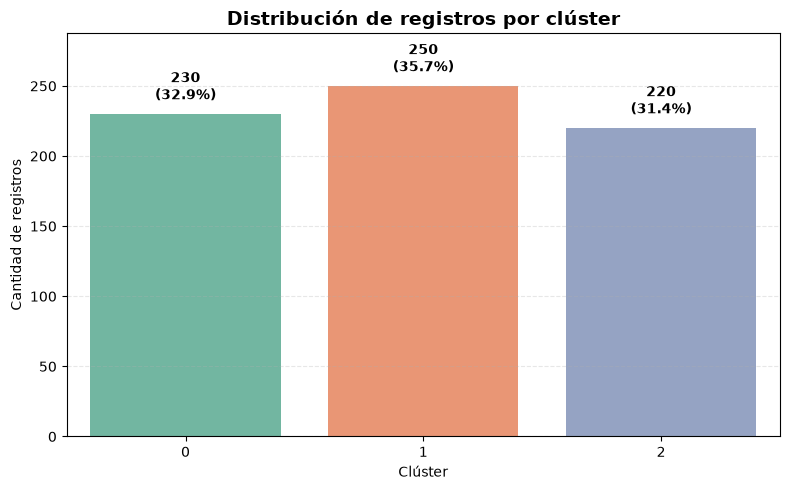

In [25]:
conteo_clusters = df['cluster'].value_counts().sort_index()

#Mostrar la tabla de frecuencias
tabla_clusters = conteo_clusters.rename_axis('Cluster').reset_index(
    name='Cantidad de registros')
tabla_clusters['Porcentaje (%)'] = (
    tabla_clusters['Cantidad de registros'] / len(df) * 100).round(2)

print("Cantidad de registros por cluster:")
print(tabla_clusters.to_string(index=False))

# Crear el gráfico de barras
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=conteo_clusters.index,
    y=conteo_clusters.values,
    hue=conteo_clusters.index,
    palette='Set2',
    legend=False
)

# Agregar cantidad y porcentaje sobre cada barra
for i, cantidad in enumerate(conteo_clusters.values):
    porcentaje = cantidad / len(df) * 100
    ax.text(
        i, cantidad + len(df) * 0.015,
        f'{cantidad}\n({porcentaje:.1f}%)',
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

plt.title('Distribución de registros por clúster',
          fontsize=14, fontweight='bold')
plt.xlabel('Clúster')
plt.ylabel('Cantidad de registros')
plt.ylim(0, conteo_clusters.max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


# Visualización de los cluster y sus centroides

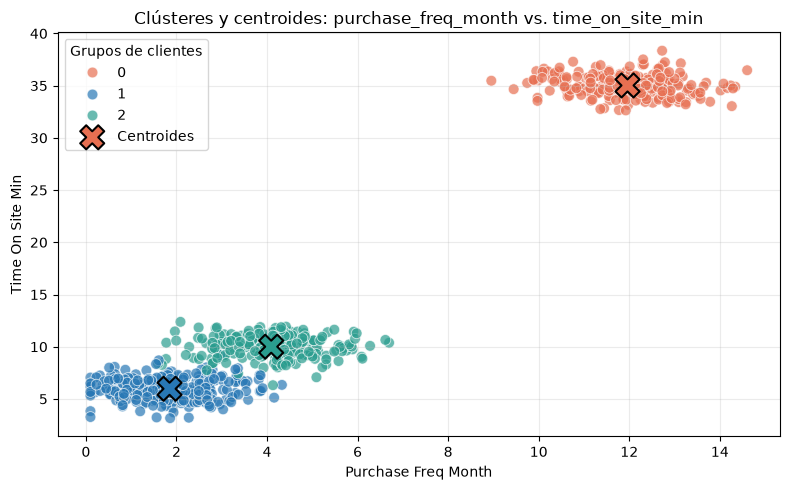

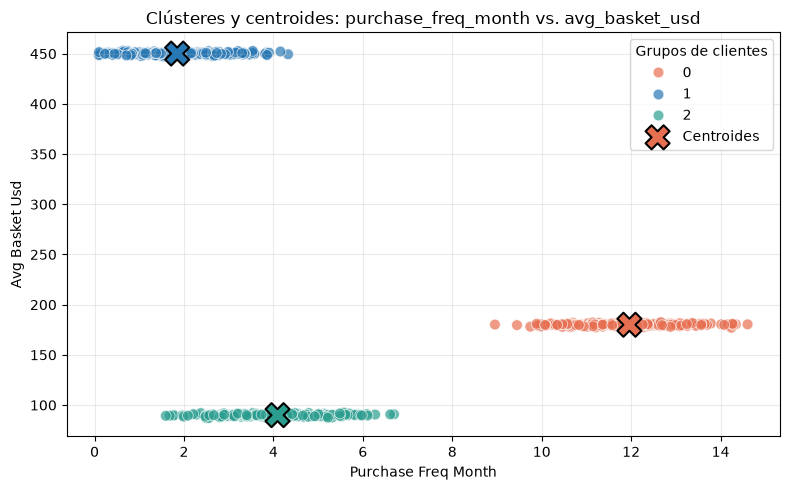

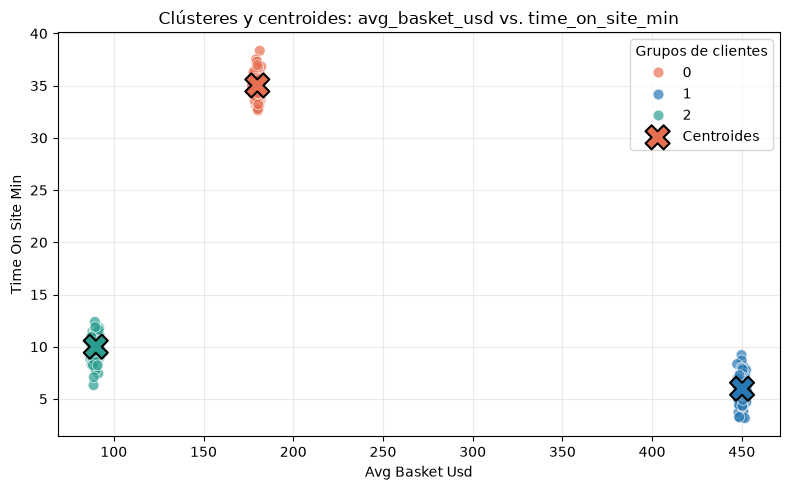

In [26]:
# Recuperar los centroides a sus unidades originales
centroides = scaler.inverse_transform(kmeans.cluster_centers_)

# Variables utilizadas al entrenar K-Means, en el mismo orden
variables = [
    'purchase_freq_month',
    'avg_basket_usd',
    'time_on_site_min',
    'discount_sensitivity'
    'returns_rate'
]

# Colores de los clústeres
colores = {0: '#E76F51', 1: '#2878B5', 2: '#2A9D8F'}

# Pares de variables a visualizar
pares = [
    ('purchase_freq_month', 'time_on_site_min'),
    ('purchase_freq_month', 'avg_basket_usd'),
    ('avg_basket_usd', 'time_on_site_min')
]

# Generar un gráfico independiente para cada par
for x, y in pares:

    plt.figure(figsize=(8, 5))

    # Graficar los clientes según su clúster
    sns.scatterplot(data=df, x=x, y=y, hue='cluster', palette=colores,
        hue_order=[0, 1, 2], s=60, alpha=0.7)

    # Ubicar las columnas correspondientes a cada variable
    indice_x = variables.index(x)
    indice_y = variables.index(y)

    # Graficar los centroides
    plt.scatter(
        centroides[:, indice_x],
        centroides[:, indice_y],
        c=[colores[i] for i in range(len(centroides))],
        marker='X',
        s=300,
        edgecolors='black',
        linewidths=1.5,
        label='Centroides',
        zorder=5
    )

    plt.xlabel(x.replace('_', ' ').title())
    plt.ylabel(y.replace('_', ' ').title())
    plt.title(f'Clústeres y centroides: {x} vs. {y}')
    plt.grid(alpha=0.25)
    plt.legend(title='Grupos de clientes', loc='best')
    plt.tight_layout()
    plt.show()


# Fronteras aproximadas de decisión

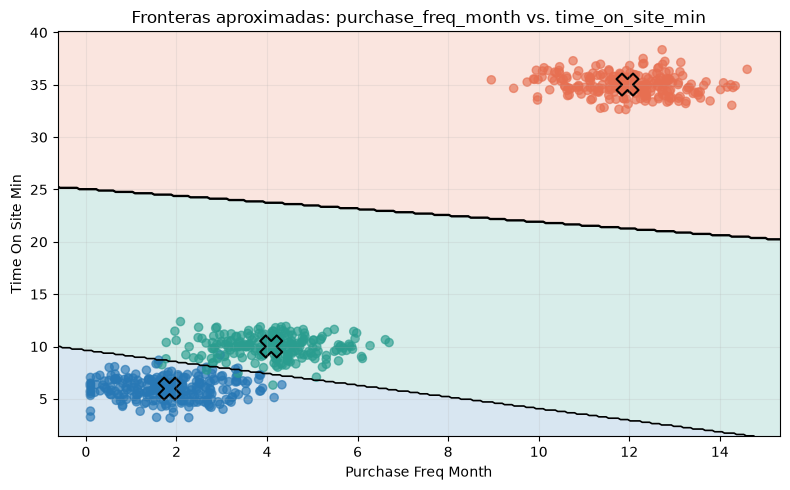

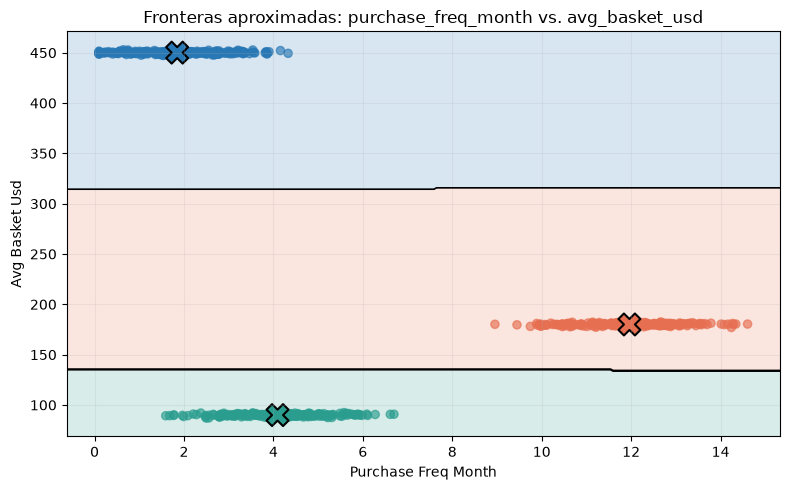

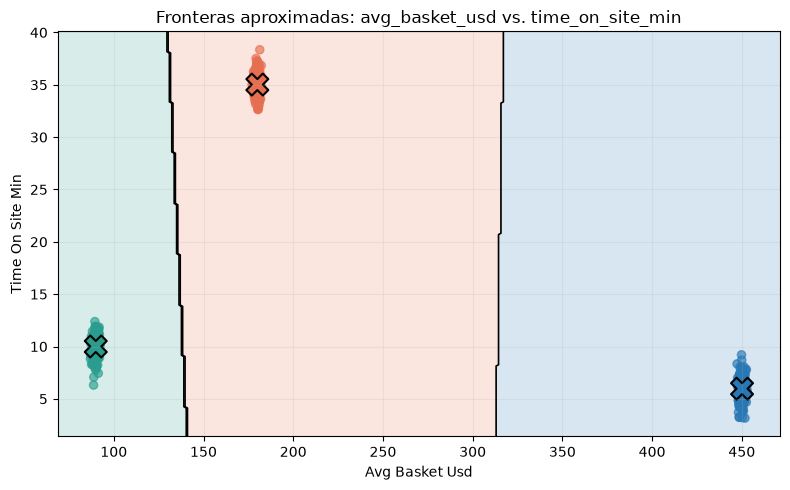

In [27]:
# Centroides en las unidades originales
centroides = scaler.inverse_transform(kmeans.cluster_centers_)

# Orden de las variables utilizadas para entrenar K-Means
variables = [
    'purchase_freq_month',
    'avg_basket_usd',
    'time_on_site_min',
    'discount_sensitivity'
    'returns_rate'
]

# Los tres pares que queremos visualizar
pares = [
    ('purchase_freq_month', 'time_on_site_min'),
    ('purchase_freq_month', 'avg_basket_usd'),
    ('avg_basket_usd', 'time_on_site_min')
]

colores = ['#E76F51', '#2878B5', '#2A9D8F']
mapa_colores = ListedColormap(colores)

for x, y in pares:

    # Datos de los ejes
    x_datos = df[x].to_numpy()
    y_datos = df[y].to_numpy()

    # Centroides proyectados sobre las dos variables
    ix = variables.index(x)
    iy = variables.index(y)

    centros_2d = centroides[:, [ix, iy]]

    # Crear una malla de puntos
    margen_x = (x_datos.max() - x_datos.min()) * 0.05
    margen_y = (y_datos.max() - y_datos.min()) * 0.05

    xx, yy = np.meshgrid(
        np.linspace(x_datos.min() - margen_x, x_datos.max() + margen_x, 300),
        np.linspace(y_datos.min() - margen_y, y_datos.max() + margen_y, 300)
    )

    malla = np.c_[xx.ravel(), yy.ravel()]

    # Asignar cada punto al centroide 2D más cercano
    distancias = cdist(malla, centros_2d)
    regiones = np.argmin(distancias, axis=1).reshape(xx.shape)

    # Graficar regiones y fronteras
    plt.figure(figsize=(8, 5))

    plt.contourf(xx, yy, regiones, levels=np.arange(-0.5, len(centros_2d) + 0.5, 1),
        cmap=mapa_colores, alpha=0.18)

    plt.contour(xx, yy, regiones, levels=np.arange(0.5, len(centros_2d) - 0.5, 1),
        colors='black', linewidths=1.2)

    # Clientes reales
    plt.scatter(x_datos, y_datos, c=df['cluster'], cmap=mapa_colores, s=35, alpha=0.65)

    # Centroides
    plt.scatter(centros_2d[:, 0], centros_2d[:, 1], marker='X', s=250,
        c=colores[:len(centros_2d)], edgecolors='black', linewidths=1.5,
        label='Centroides')

    plt.xlabel(x.replace('_', ' ').title())
    plt.ylabel(y.replace('_', ' ').title())
    plt.title(f'Fronteras aproximadas: {x} vs. {y}')
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


# Predicción de nuevos clientes

In [28]:
nuevo_cliente = pd.DataFrame([{
    "purchase_freq_month": 3.50,
    "avg_basket_usd": 320.00,
    "time_on_site_min": 12.50,
    "discount_sensitivity": 0.60,
    "returns_rate": 0.20,
}])

nuevo_cliente_scaled = scaler.transform(nuevo_cliente)

prediccion = kmeans.predict(nuevo_cliente_scaled)

print(prediccion)

[1]


In [29]:
# Otro cliente compra pocas veces, gasta poco por compra, permanece poco tiempo en el sitio 
# y casi no es sensible a los descuentos.
nuevo_cliente = pd.DataFrame([{
    "purchase_freq_month": 0.50,
    "avg_basket_usd": 95.00,
    "time_on_site_min": 4.00,
    "discount_sensitivity": 0.05,
    "returns_rate": 0.00,
}])

nuevo_cliente_scaled = scaler.transform(nuevo_cliente)

prediccion = kmeans.predict(nuevo_cliente_scaled)

print(prediccion)

[2]


# Interpretación de los clústeres obtenidos mediante K-Means
Se muestra las características promedio de cada cluster para comprender qué tipo de clientes representa.

In [30]:
df.groupby('cluster').mean()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
cluster,,,,,
0,11.961153,179.999315,35.022131,0.541539,0.332461
1,1.846908,450.123746,5.973739,0.358088,0.375371
2,4.091883,89.957567,10.003793,0.379465,0.298761


Analizando los promedios de las variables, se identificaron tres perfiles diferenciados de clientes.

El **clúster 0** se caracteriza por una frecuencia de compra elevada, un importe promedio de USD 180 y la mayor sensibilidad a los descuentos. Representa un segmento de clientes recurrentes para el cual podrían diseñarse estrategias de fidelización y promociones controladas. Conviene evaluar si los descuentos generan compras adicionales o reducen innecesariamente el margen de ganancia.

El **clúster 1** agrupa a clientes con una frecuencia de compra baja, pero con el mayor importe promedio por operación, de aproximadamente USD 450. Además, registra el menor tiempo de permanencia en el sitio y la mayor tasa de devolución. Podrían ser compradores que encuentran rápidamente lo que buscan o que adquieren productos de mayor valor. Sería conveniente investigar su tasa de devolución, la más alta del conjunto, y desarrollar acciones para incentivar nuevas compras.

El **clúster 2** presenta un comportamiento intermedio en frecuencia de compra, el menor importe promedio y la menor tasa de devolución. Este segmento podría abordarse mediante estrategias de venta complementaria y acciones destinadas a incrementar el valor promedio de las compras.

En conclusión, la segmentación permite identificar comportamientos comerciales diferentes y proponer estrategias específicas para cada grupo. Estas recomendaciones constituyen hipótesis de negocio que deberían validarse con información adicional, como el margen de ganancia, el costo de los descuentos y los motivos de devolución.

# A continuación vamos a identificar los patrones solicitados
**Patrón 1:** frecuencia alta + ticket bajo + alta sensibilidad a descuentos.

**Patrón 2:** frecuencia baja + ticket alto + baja sensibilidad a descuentos.

**Patrón 3:** diferencias entre tiempo de permanencia y tasa de devoluciones.

Este código calcula los promedios por clúster, los compara con los promedios generales y marca qué grupos cumplen los patrones definidos. Como no tenemos umbrales comerciales establecidos, usaremos inicialmente valores relativos a la media general.

In [33]:
variables = [
    'purchase_freq_month',
    'avg_basket_usd',
    'time_on_site_min',
    'discount_sensitivity',
    'returns_rate'
]

# Promedios por clúster
perfil = df.groupby('cluster')[variables].mean()

# Promedio general del dataset
promedio_general = df[variables].mean()

print("Promedios por clúster:")
display(perfil.round(3))

print("\nPromedios generales:")
display(promedio_general.round(3))

# Comparación relativa: mayor o menor que la media general
comparacion = perfil.gt(promedio_general)

print("\n¿Cada variable supera el promedio general?")
display(comparacion)


Promedios por clúster:


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
cluster,,,,,
0,11.961,179.999,35.022,0.542,0.332
1,1.847,450.124,5.974,0.358,0.375
2,4.092,89.958,10.004,0.379,0.299



Promedios generales:


purchase_freq_month       5.876
avg_basket_usd          248.173
time_on_site_min         16.785
discount_sensitivity      0.425
returns_rate              0.337
dtype: float64


¿Cada variable supera el promedio general?


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
cluster,,,,,
0,True,False,True,True,False
1,False,True,False,False,True
2,False,False,False,False,False


# Detectar los tres patrones

In [34]:
# Patrón 1:
# Frecuencia alta, ticket bajo y sensibilidad alta
patron_1 = perfil[
    (perfil['purchase_freq_month'] > promedio_general['purchase_freq_month']) &
    (perfil['avg_basket_usd'] < promedio_general['avg_basket_usd']) &
    (perfil['discount_sensitivity'] > promedio_general['discount_sensitivity'])
]

# Patrón 2:
# Frecuencia baja, ticket alto y sensibilidad baja
patron_2 = perfil[
    (perfil['purchase_freq_month'] < promedio_general['purchase_freq_month']) &
    (perfil['avg_basket_usd'] > promedio_general['avg_basket_usd']) &
    (perfil['discount_sensitivity'] < promedio_general['discount_sensitivity'])
]

# Patrón 3:
# Comparar tiempo en el sitio y tasa de devoluciones
patron_3 = perfil[
    ['time_on_site_min', 'returns_rate']
].sort_values('time_on_site_min', ascending=False)

print("PATRÓN 1: Frecuencia alta, ticket bajo y sensibilidad alta")
display(patron_1.round(3))

print("PATRÓN 2: Frecuencia baja, ticket alto y sensibilidad baja")
display(patron_2.round(3))

print("PATRÓN 3: Tiempo en el sitio y tasa de devoluciones")
display(patron_3.round(3))


PATRÓN 1: Frecuencia alta, ticket bajo y sensibilidad alta


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
cluster,,,,,
0,11.961,179.999,35.022,0.542,0.332


PATRÓN 2: Frecuencia baja, ticket alto y sensibilidad baja


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
cluster,,,,,
1,1.847,450.124,5.974,0.358,0.375


PATRÓN 3: Tiempo en el sitio y tasa de devoluciones


,time_on_site_min,returns_rate
cluster,,
0,35.022,0.332
2,10.004,0.299
1,5.974,0.375
